# Task 1: Predicting House Prices with Linear Regression
## 1. Environment Setup & Library Imports
Importing essential libraries for data manipulation, visualization, model training, and evaluation.

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score

# Aesthetics setup
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Exploratory Data Analysis (EDA)
Loading the house price dataset, checking structure, missing values, and generating descriptive statistics.

In [12]:
df = pd.read_csv("house_data.csv")

print("Dataset Shape:", df.shape)
print("\n--- Missing Values Count ---")
print(df.isnull().sum())

print("\n--- Summary Statistics ---")
display(df.describe())

Dataset Shape: (2000, 10)

--- Missing Values Count ---
Id           0
Area         0
Bedrooms     0
Bathrooms    0
Floors       0
YearBuilt    0
Location     0
Condition    0
Garage       0
Price        0
dtype: int64

--- Summary Statistics ---


,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Price
count,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000
mean,1000.500000,2786.209500,3.003500,2.55250,1.993500,1961.446000,537676.855000
std,577.494589,1295.146799,1.424606,1.10899,0.809188,35.926695,276428.845719
min,1.000000,501.000000,1.000000,1.00000,1.000000,1900.000000,50005.000000
25%,500.750000,1653.000000,2.000000,2.00000,1.000000,1930.000000,300098.000000
50%,1000.500000,2833.000000,3.000000,3.00000,2.000000,1961.000000,539254.000000
75%,1500.250000,3887.500000,4.000000,4.00000,3.000000,1993.000000,780086.000000
max,2000.000000,4999.000000,5.000000,4.00000,3.000000,2023.000000,999656.000000


## 3. Distribution of the Target Variable (`Price`)
Visualizing the distribution of house prices using a histogram and KDE to inspect skewness and outliers.

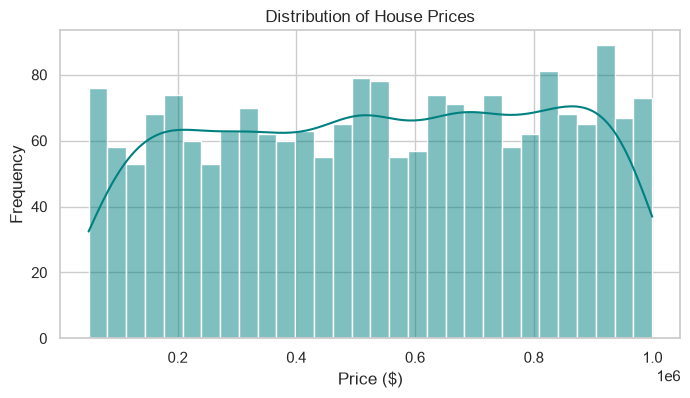

In [13]:
plt.figure(figsize=(8, 4))
sns.histplot(df["Price"], kde=True, bins=30, color="teal")
plt.title("Distribution of House Prices")
plt.xlabel("Price ($)")
plt.ylabel("Frequency")
plt.show()

## 4. Feature Selection Discussion
### Rationale for Feature Selection:
- **Area, Bedrooms, Bathrooms, Floors:** Primary indicators of livable capacity. Larger physical dimensions directly drive construction and asset value.
- **YearBuilt:** Reflects property age and depreciation. Newer structures typically demand higher market value.
- **Location:** Geographic baseline determines proximity to commerce and lifestyle amenities.
- **Condition & Garage:** Secondary drivers accounting for maintenance quality and practical utility.
- **Drop `Id`:** `Id` is merely a row identifier without economic predictive power.

## 5. Data Preprocessing & Categorical Encoding
- Dropping irrelevant identifier columns.
- Imputing missing numerical values using median and categorical values using mode.
- Encoding categorical features (`Location`, `Condition`, `Garage`) using One-Hot Encoding (`pd.get_dummies`).

In [14]:
# Drop ID
df_clean = df.drop(columns=["Id"])

# Split features and target
X = df_clean.drop(columns=["Price"])
y = df_clean["Price"]

# Missing value handling
num_cols = X.select_dtypes(include=["int64", "float64"]).columns
cat_cols = X.select_dtypes(include=["object"]).columns

for col in num_cols:
    X[col] = X[col].fillna(X[col].median())

for col in cat_cols:
    X[col] = X[col].fillna(X[col].mode()[0])

# One-Hot Encoding
X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=True)
print(f"Total features after encoding: {X_encoded.shape[1]}")
X_encoded.head()

Total features after encoding: 12


C:\Users\Janhavi\AppData\Local\Temp\ipykernel_20456\4017090475.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object"]).columns


,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location_Rural,Location_Suburban,Location_Urban,Condition_Fair,Condition_Good,Condition_Poor,Garage_Yes
0,1360,5,4,3,1970,False,False,False,False,False,False,False
1,4272,5,4,3,1958,False,False,False,False,False,False,False
2,3592,2,2,3,1938,False,False,False,False,True,False,False
3,966,4,2,2,1902,False,True,False,True,False,False,True
4,4926,1,4,2,1975,False,False,False,True,False,False,True


## 6. Correlation Heatmap
Identifying linear correlation between all independent features and the target variable (`Price`).

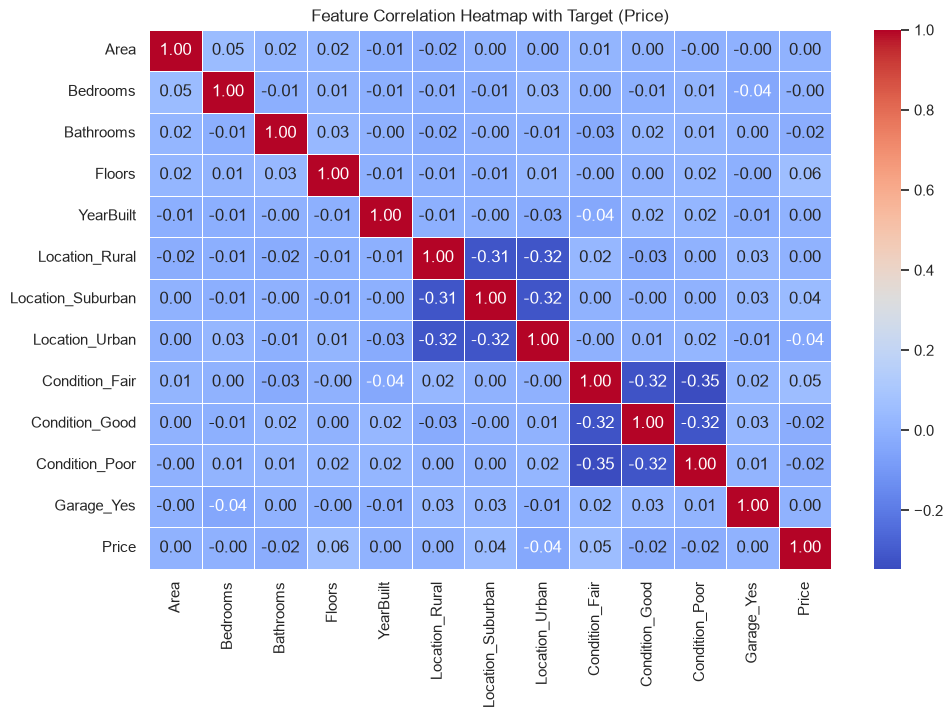

In [15]:
full_df = pd.concat([X_encoded, y], axis=1)

plt.figure(figsize=(11, 7))
sns.heatmap(full_df.corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Feature Correlation Heatmap with Target (Price)")
plt.show()

## 7. Train/Test Split (80/20) & Linear Regression Training
Partitioning data into 80% training and 20% testing subsets, then fitting an ordinary least squares `LinearRegression` model.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.20, random_state=42
)

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

y_pred = lr_model.predict(X_test)
print("Linear Regression model successfully trained.")

Linear Regression model successfully trained.


## 8. Model Evaluation
Evaluating model performance using:
- **Mean Squared Error (MSE)**
- **Root Mean Squared Error (RMSE)**
- **Coefficient of Determination ($R^2$ Score)**

In [17]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE)      : {mse:,.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:,.2f}")
print(f"R² Score                      : {r2:.4f}")

Mean Squared Error (MSE)      : 78,321,466,146.03
Root Mean Squared Error (RMSE): 279,859.73
R² Score                      : -0.0067


## 9. Diagnostic Plots
- **Actual vs. Predicted Plot:** Evaluates variance around the ideal identity line.
- **Residual Plot:** Verifies that errors are randomly distributed around 0 with no systematic pattern.

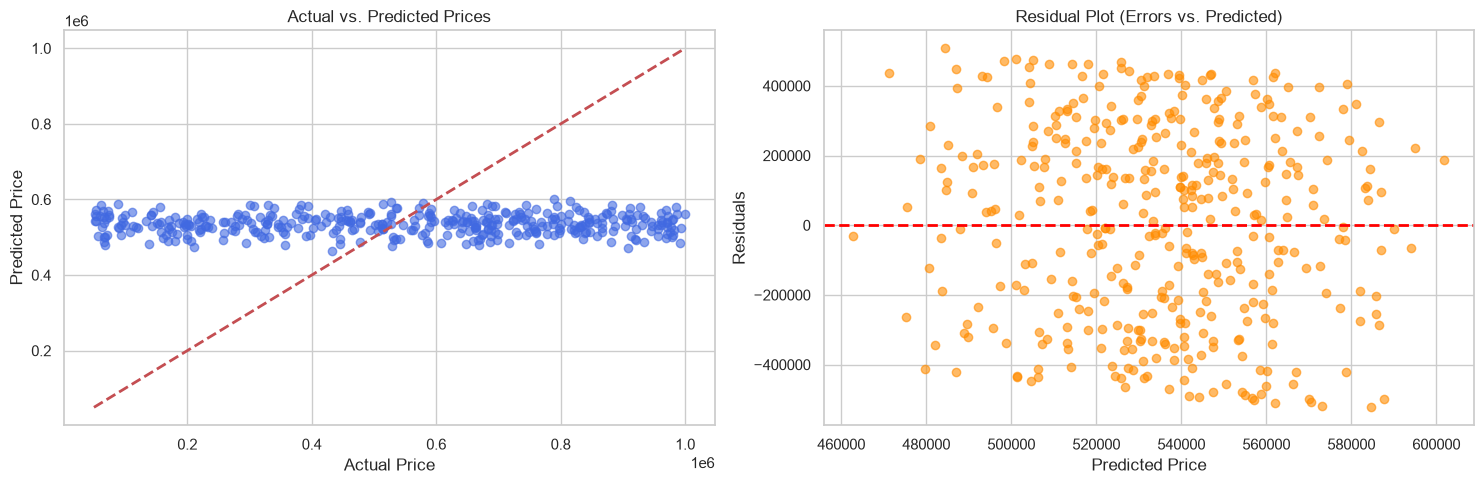

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Actual vs Predicted
axes[0].scatter(y_test, y_pred, alpha=0.6, color="royalblue")
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], "r--", lw=2)
axes[0].set_title("Actual vs. Predicted Prices")
axes[0].set_xlabel("Actual Price")
axes[0].set_ylabel("Predicted Price")

# Residual Plot
residuals = y_test - y_pred
axes[1].scatter(y_pred, residuals, alpha=0.6, color="darkorange")
axes[1].axhline(y=0, color="red", linestyle="--", lw=2)
axes[1].set_title("Residual Plot (Errors vs. Predicted)")
axes[1].set_xlabel("Predicted Price")
axes[1].set_ylabel("Residuals")

plt.tight_layout()
plt.show()

## 10. Model Coefficient Analysis
Inspecting model weights to assess which features impart the strongest positive and negative effects on predicted price.

In [19]:
coeff_df = pd.DataFrame({
    "Feature": X_encoded.columns,
    "Coefficient": lr_model.coef_
})

print("Top Positive Drivers:")
display(coeff_df.sort_values(by="Coefficient", ascending=False).head(5))

print("\nTop Negative Drivers:")
display(coeff_df.sort_values(by="Coefficient", ascending=True).head(5))

Top Positive Drivers:


,Feature,Coefficient
8,Condition_Fair,24083.307846
3,Floors,23727.983633
6,Location_Suburban,11511.989815
10,Condition_Poor,4073.268930
11,Garage_Yes,2373.530579



Top Negative Drivers:


,Feature,Coefficient
9,Condition_Good,-12941.044835
7,Location_Urban,-12718.918912
2,Bathrooms,-9662.248234
0,Area,-0.575754
1,Bedrooms,76.784827


## 11. (Bonus) Regularization Comparison: Linear vs. Ridge Regression
Applying L2-regularized Ridge Regression to penalize large weights and compare stability against the baseline Linear Regression model.

In [20]:
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, y_train)

y_pred_ridge = ridge_model.predict(X_test)

ridge_rmse = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
ridge_r2 = r2_score(y_test, y_pred_ridge)

comparison_df = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge Regression (L2)"],
    "RMSE": [rmse, ridge_rmse],
    "R² Score": [r2, ridge_r2]
})

display(comparison_df)

,Model,RMSE,R² Score
0,Linear Regression,279859.725838,-0.006718
1,Ridge Regression (L2),279859.372593,-0.006715
